In [3]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing import image
warnings.filterwarnings('ignore')

In [4]:
def get_random_images(filepath, n=50):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [5]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [6]:
def get_imdb_data(imdb_id):
    """Fetch and parse IMDB page data."""
    url = f'https://www.imdb.com/title/{imdb_id}/'
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

    try:
        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.text, 'html.parser')
        script = soup.find('script', {'type': 'application/ld+json'})
        if not script:
            return None
        
        import json
        data = json.loads(script.string)
        
        show_data = {
            'imdb_id': imdb_id,
            'title': data.get('name', ''),
            'rating': data.get('aggregateRating', {}).get('ratingValue', 0),
            'rating_count': data.get('aggregateRating', {}).get('ratingCount', 0),
            'content_rating': data.get('contentRating', ''),
            'date_published': data.get('datePublished', ''),
            'genre_count': len(data.get('genre', [])),
        }
        
        return show_data
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [7]:
def extract_cnn_features(image_path):
    """Extract features using ResNet50."""
    # Load the ResNet50 model pre-trained on ImageNet
    model = ResNet50(weights='imagenet', include_top=False, pooling='avg')
    
    # Load and preprocess the image
    img = image.load_img(image_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)
    
    # Extract features
    features = model.predict(img_array)
    return features.flatten()

In [8]:
def perform_pca_analysis(feature_df):
    """Perform PCA on features."""
    # Prepare feature matrix
    X = feature_df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    return pca, X_pca, n_components

In [9]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]  # Limit to n_components
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))  # Ensure x-ticks match the number of components
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines for better readability
    plt.show()

In [10]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [11]:
def plot_pca_features(pca, feature_names, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    # Get the feature loadings
    components = pca.components_
    
    # Create scatter plot
    for i, feature in enumerate(feature_names):
        plt.scatter(components[0, i], components[1, i])
        #plt.annotate(feature, (components[0, i], components[1, i]))
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [12]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [13]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 3D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131, projection='3d')
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    ax1.set_zlabel('PC3')
    
    # Hierarchical
    ax2 = fig.add_subplot(132, projection='3d')
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    ax2.set_zlabel('PC3')
    
    # DBSCAN
    ax3 = fig.add_subplot(133, projection='3d')
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    ax3.set_zlabel('PC3')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [ ]:
def create_dataset(image_folder):
    """Create dataset by extracting features and IMDb data."""
    imdb_data = []
    feature_data = []
    
    # Get random images
    image_files = get_random_images(image_folder)
    
    for img_file in image_files:
        imdb_id = extract_imdb_id(img_file)
        imdb_info = get_imdb_data(imdb_id)
        
        if imdb_info:
            imdb_data.append(imdb_info)
            
            # Extract CNN features
            img_path = os.path.join(image_folder, img_file)
            features = extract_cnn_features(img_path)
            
            # Create feature dictionary
            feature_dict = {'imdb_id': imdb_id}
            for i, val in enumerate(features):
                feature_dict[f'feature_{i}'] = val
            feature_data.append(feature_dict)
    
    # Convert to DataFrames
    imdb_df2 = pd.DataFrame(imdb_data)
    feature_df2 = pd.DataFrame(feature_data)
    
    # Save datasets
    imdb_df2.to_csv('imdb_data.csv', index=False)
    feature_df2.to_csv('feature_data.csv', index=False)
    
    return imdb_df2, feature_df2

In [15]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "imdb_show_images"
imdb_df, feature_df = create_dataset(IMAGE_FOLDER) 

Step 1: Gathering data...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━

In [16]:
print("\nIMDB Data Sample:")
print(imdb_df.head())


IMDB Data Sample:
     imdb_id            title  rating  rating_count content_rating  \
0  tt0459159  The Thick of It     8.7         27702          TV-MA   
1  tt1586680        Shameless     8.5        305004           R-16   
2  tt0072500    Fawlty Towers     8.8        104221          TV-PG   
3  tt3398540         Haikyû!!     8.7         42336          PG-13   
4  tt9253866       Our Planet     9.2         55706          TV-PG   

  date_published  genre_count  
0     2005-05-19            1  
1     2011-01-09            2  
2     1975-09-19            1  
3     2015-04-06            3  
4     2019-04-05            1  


In [17]:
print("\nFeature Data Sample:")
print(feature_df.head())


Feature Data Sample:
     imdb_id  feature_0  feature_1  feature_2  feature_3  feature_4  \
0  tt0459159   0.205079   1.941450   0.552307   2.234753   0.446100   
1  tt1586680   0.095488   1.639962   0.168572   0.251036   0.280576   
2  tt0072500   0.095807   0.287502   0.002058   0.000000   0.104576   
3  tt3398540   0.069916   3.860058   0.014750   0.086100   0.065619   
4  tt9253866   0.132811   0.147087   0.178977   0.310979   0.406783   

   feature_5  feature_6  feature_7  feature_8  ...  feature_2038  \
0   0.066442   0.981258   1.751038   0.008316  ...      0.301807   
1   0.117587   0.398356   0.295618   0.564448  ...      0.694976   
2   0.215885   0.010461   2.234959   0.075813  ...      0.153992   
3   0.069988   0.073715   0.252967   1.387031  ...      0.385445   
4   0.573025   0.005861   0.068016   0.023195  ...      0.257384   

   feature_2039  feature_2040  feature_2041  feature_2042  feature_2043  \
0      0.020866      2.897730      0.019851      0.713480      0.07

In [24]:
# 4-8. PCA Analysis
print("\nStep 4-8: Performing PCA analysis...")
feature_names = feature_df.drop('imdb_id', axis=1).columns
pca, X_pca, n_components = perform_pca_analysis(feature_df)

# Set display precision for floating-point numbers
pd.set_option('display.float_format', '{:.6f}'.format)

print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
print(evr)


Step 4-8: Performing PCA analysis...

Explained variance ratios:
                     Explained Variance Ratio
Principal Component                          
PC1                                  0.062674
PC2                                  0.057530
PC3                                  0.054727
PC4                                  0.047506
PC5                                  0.041305
PC6                                  0.038313
PC7                                  0.035389
PC8                                  0.033425
PC9                                  0.031023
PC10                                 0.029544
PC11                                 0.027942
PC12                                 0.025801
PC13                                 0.024856
PC14                                 0.024032
PC15                                 0.022416
PC16                                 0.021776
PC17                                 0.020855
PC18                                 0.019827
PC19          

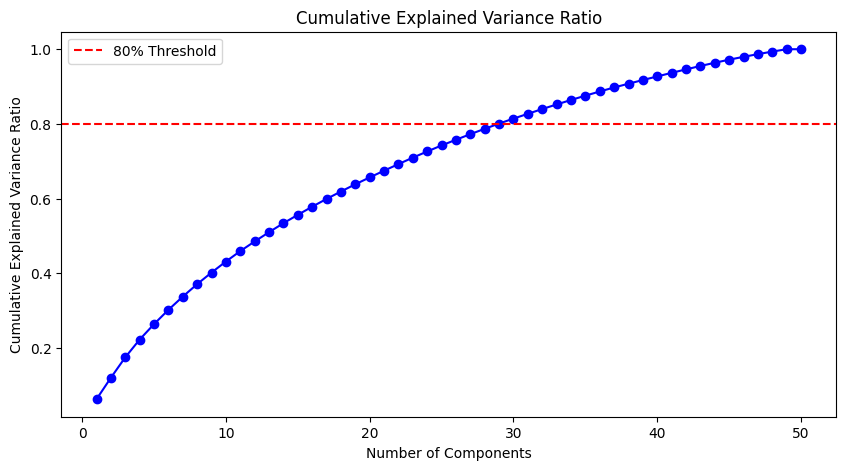

In [19]:
plot_cumulative_variance(pca)

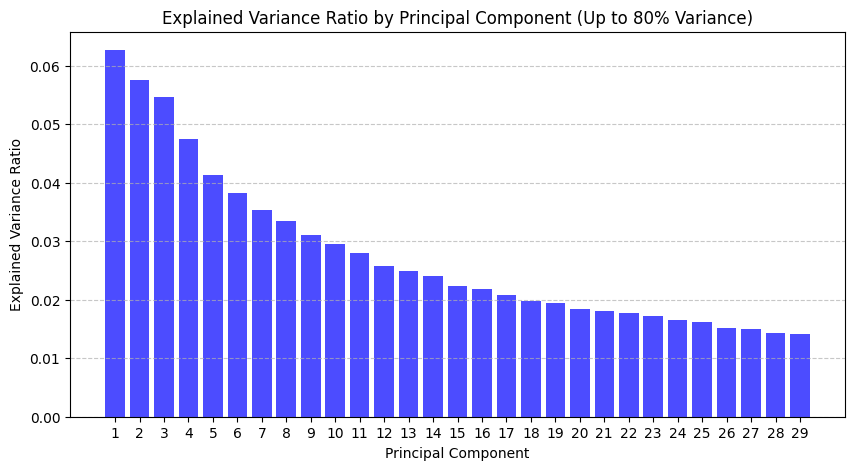

In [20]:
plot_explained_variance(pca, n_components)

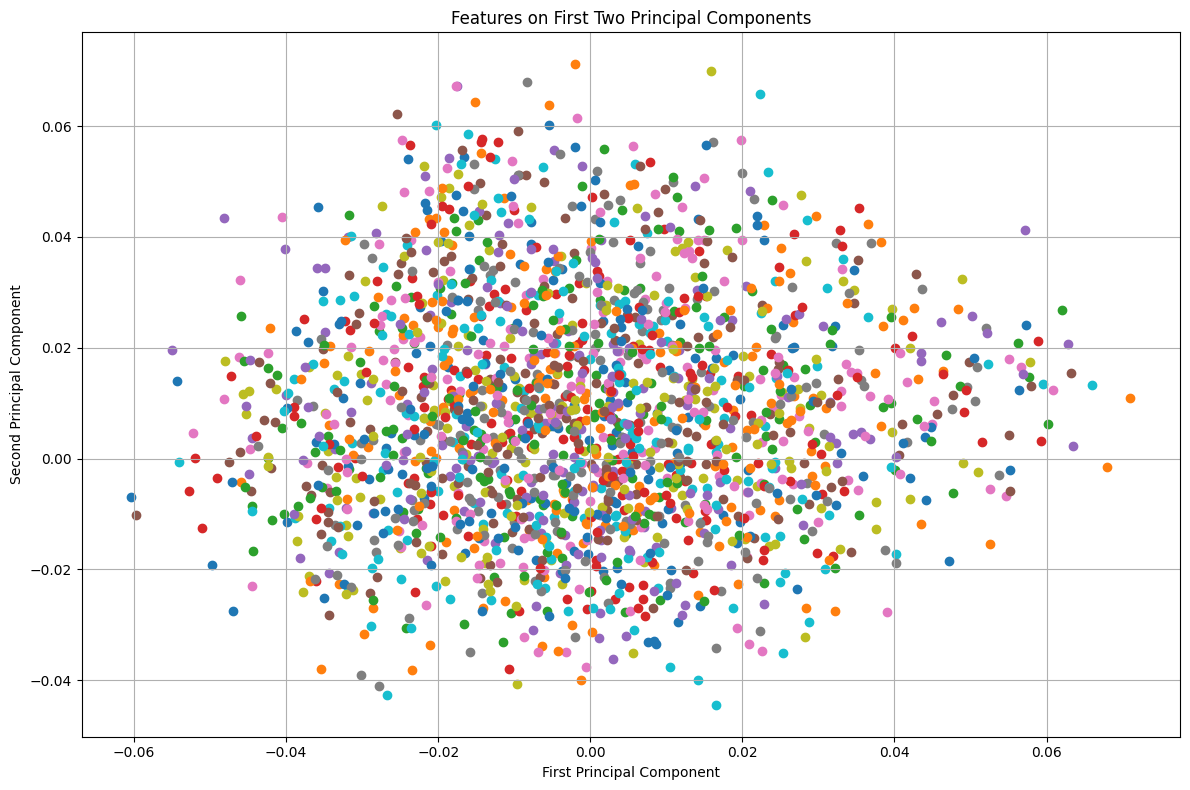

In [21]:
plot_pca_features(pca, feature_names, n_components)

In [22]:
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
print(loadings_df)

                   PC1       PC2       PC3       PC4       PC5       PC6  \
feature_0    -0.161742  0.235326 -0.168601 -0.191028 -0.196455 -0.013275   
feature_1     0.334103 -0.034269 -0.333882 -0.130993 -0.172216  0.126731   
feature_2    -0.246632 -0.018532 -0.137869 -0.077533  0.265602 -0.078161   
feature_3    -0.260613 -0.119196 -0.015850 -0.098238  0.127909 -0.172302   
feature_4    -0.459016  0.415608 -0.027608 -0.096361 -0.281601 -0.088967   
...                ...       ...       ...       ...       ...       ...   
feature_2043  0.318234  0.300212 -0.077861  0.117267 -0.176687 -0.137004   
feature_2044  0.052169  0.041075  0.282265 -0.241070  0.173934 -0.053329   
feature_2045  0.100006 -0.114423  0.192704 -0.117294  0.084827 -0.001568   
feature_2046  0.098524  0.360978  0.228437 -0.120132 -0.299317 -0.010066   
feature_2047  0.106634  0.029970  0.089583  0.460704  0.344245 -0.076845   

                   PC7       PC8       PC9      PC10  ...      PC20      PC21  \
featur


Step 9-12: Performing clustering analysis...


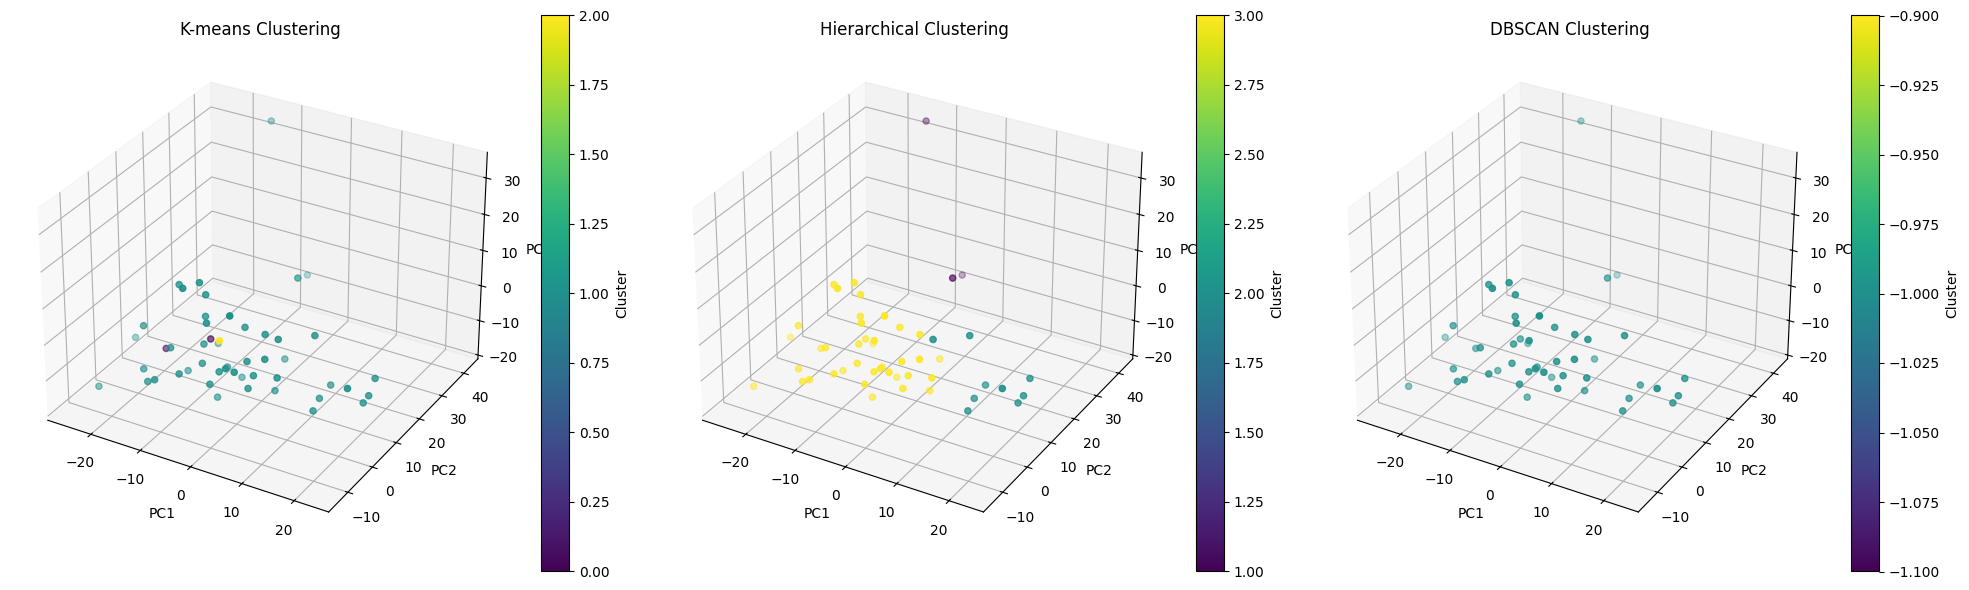

In [23]:
# 9-12. Clustering Analysis
print("\nStep 9-12: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)